In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def generate_func(params, num_points, noise_std):
    X_func = np.linspace(0, 10, num_points)
    Y_func = X_func**params*0.0042-X_func**(params-0.01)*0.067+X_func**(params-1)*0.67-1.488

    # Добавляем шум к каждой координате
    X_noisy = X_func + np.random.normal(loc=0.0, scale=noise_std, size=num_points)
    Y_noisy = Y_func + np.random.normal(loc=0.0, scale=noise_std, size=num_points)

    # Объединяем координаты в один массив размером (num_points, 2)
    points = np.column_stack((X_noisy, Y_noisy))

    return points

points = generate_func(5, 67, 0.05)

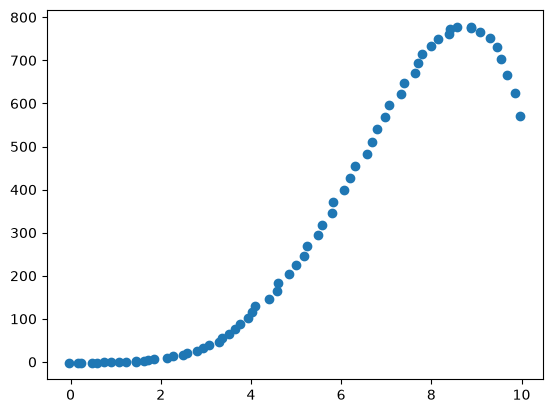

In [3]:
plt.scatter(points[:,0], points[:,1])

In [4]:
# шаг 1
class NeuralNetBias:
    def __init__(self, hidden_size=10):
        self.w1 = np.random.normal(size=(hidden_size, 1))
        self.bias1 = np.random.normal(size=(hidden_size,1))
        
        self.w2 = np.random.normal(size=(1,hidden_size))
        self.bias2 = np.random.normal(size=(1,1))

    def loss(self, output, target):
        return np.mean(np.abs(target-output))

    def forward(self, x, w1=None, bias1=None, w2=None, bias2=None):
        if w1 is None:
            w1 = self.w1
        if w2 is None:
            w2 = self.w2
        if bias1 is None:
            bias1 = self.bias1
        if bias2 is None:
            bias2 = self.bias2
            
        x = w1@x + bias1
        x = np.maximum(0, x)
        x = w2@x + bias2
        return x

    def train_step(self, X, Y, lr=0.1):
        d_w1 = np.random.normal(size=self.w1.shape)
        d_bias1 = np.random.normal(size=self.bias1.shape)
        
        d_w2 = np.random.normal(size=self.w2.shape)
        d_bias2 = np.random.normal(size=self.bias2.shape)

        plus_w1 = self.w1 + lr*d_w1
        plus_bias1 = self.bias1 + lr*d_bias1
        
        plus_w2 = self.w2 + lr*d_w2
        plus_bias2 = self.bias2 + lr*d_bias2

        minus_w1 = self.w1 - lr*d_w1
        minus_bias1 = self.bias1 - lr*d_bias1
        
        minus_w2 = self.w2 - lr*d_w2
        minus_bias2 = self.bias2 - lr*d_bias2
        
        cur_output = self.forward(X)
        plus_output = self.forward(X, plus_w1, plus_bias1, plus_w2, plus_bias2)
        minus_output = self.forward(X, minus_w1, minus_bias1, minus_w2, minus_bias2)
    
        if self.loss(cur_output, Y) > self.loss(plus_output, Y):
            self.w1 = plus_w1
            self.bias1 = plus_bias1
            
            self.w2 = plus_w2
            self.bias2 = plus_bias2
        elif self.loss(cur_output, Y) > self.loss(minus_output, Y):
            self.w1 = minus_w1
            self.bias1 = minus_bias1
            
            self.w2 = minus_w2
            self.bias2 = minus_bias2


In [5]:
model_b = NeuralNetBias()

X_train = points[:, 0].reshape(1, -1)
Y_train = points[:, 1].reshape(1, -1)
X_mean = np.mean(X_train)
X_std = np.std(X_train)
X_train_norm = (X_train - X_mean) / X_std

In [6]:
# шаг 2
iterations = 100_000
initial_lr = 0.5

for i in range(iterations):
    current_lr = initial_lr * (1 - i / iterations)
    model_b.train_step(X_train_norm, Y_train, lr=current_lr)

In [7]:
# шаг 3
Y_new = model_b.forward(X_train_norm)

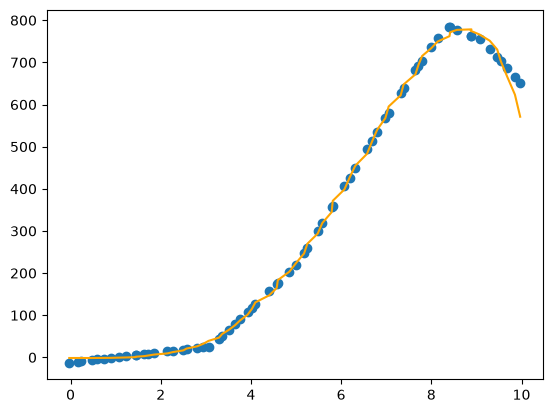

In [8]:
# шаг 4
plt.plot(points[:,0], points[:,1], color='orange')
plt.scatter(points[:,0], Y_new)

In [10]:
# шаг 5
def print_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred)**2)
    rmse = np.sqrt(mse)
    
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1 - (ss_res / ss_tot)
    
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R^2:  {r2:.4f}")

print_metrics(Y_train, Y_new)

MAE:  8.2155
RMSE: 13.6777
R^2:  0.9979
